In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
df=pd.read_csv('cleaned_used_cars_dataset.csv')
print(df.shape)
df.head()

(2901, 18)


,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
0,CAR-52762,MG,Zs,2021,64900.0,Automatic,Diesel,1500.0,SUV,Black,Giza,Individual,No,1.0,Fair,8.0,655000,Yes
1,CAR-52678,Kia,Cerato,2023,42100.0,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1.0,Good,12.0,1012000,No
2,CAR-52822,Skoda,Octavia,2009,224500.0,Automatic,Petrol,1400.0,Sedan,Silver,Banha,Dealer,Yes,2.0,Fair,11.0,229000,No
3,CAR-51133,Fiat,Tipo,2019,103800.0,Automatic,Petrol,1600.0,Sedan,Silver,Alexandria,Individual,No,2.0,Fair,7.0,319000,No
4,CAR-51465,Mitsubishi,Lancer,2022,50200.0,Manual,Hybrid,1600.0,Sedan,White,Cairo,Individual,No,2.0,Fair,8.0,425000,No


In [3]:
print("\nTarget values:")
print(df["sold_within_30_days"].value_counts(dropna=False))


Target values:
sold_within_30_days
No     1582
Yes    1319
Name: count, dtype: int64


## Correlation Heatmap — Numerical Features

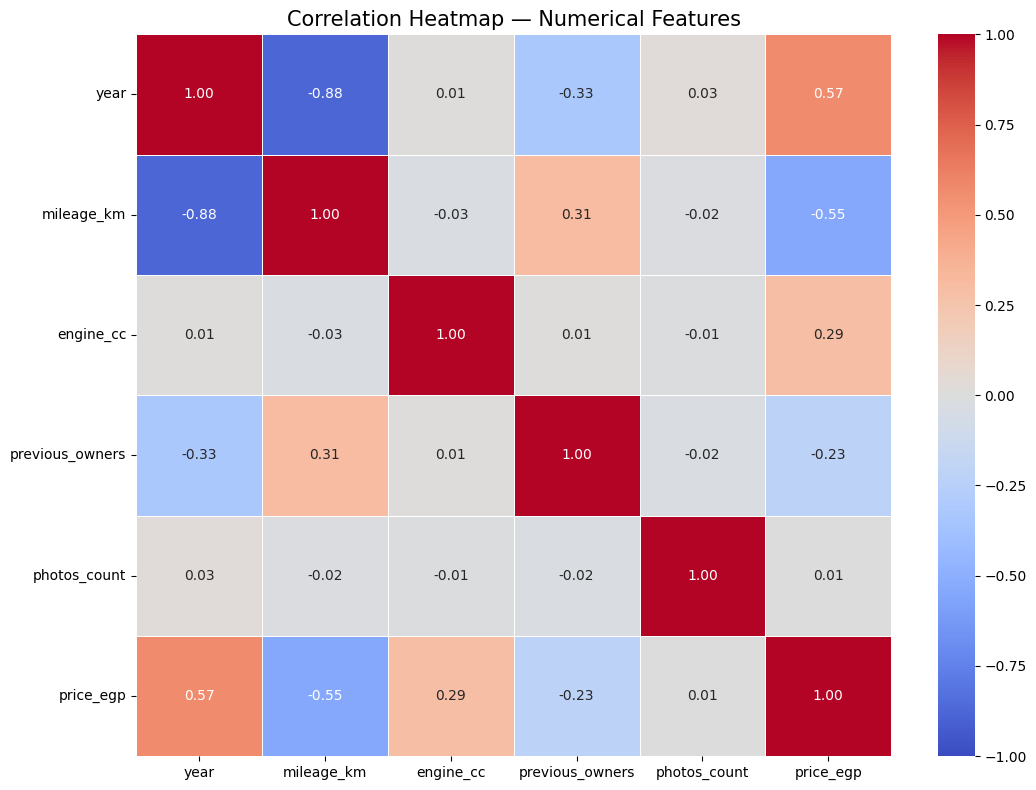

In [4]:
numerical_cols = [
    "year",
    "mileage_km",
    "engine_cc",
    "previous_owners",
    "photos_count",
    "price_egp"
]


corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap — Numerical Features", fontsize=15)
plt.tight_layout()
plt.show()

## Correlation Heatmap — Numerical Features vs Target

In [5]:
df["sold_within_30_days_num"] = (
    df["sold_within_30_days"]
    .map({"No": 0, "Yes": 1})
)

In [6]:
target_cols = numerical_cols + ["sold_within_30_days_num"]

In [7]:
target_corr = (
    df[target_cols]
    .corr()["sold_within_30_days_num"]
    .drop("sold_within_30_days_num")
    .sort_values()
)

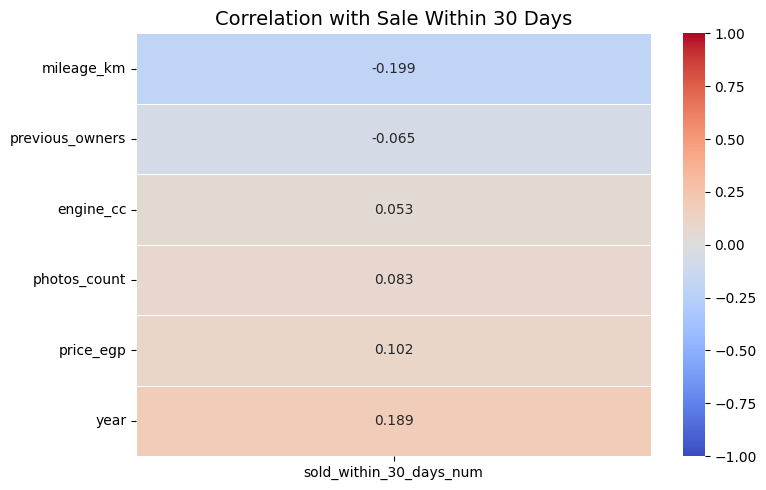

In [8]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    target_corr.to_frame(),
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation with Sale Within 30 Days", fontsize=14)
plt.tight_layout()
plt.show()

## Scatter Plot — Year vs Price

In [9]:
fig = px.scatter(
    df,
    x="year",
    y="price_egp",
    color="sold_within_30_days",
    hover_data=["brand", "model", "mileage_km", "engine_cc"],
    title="Scatter Plot — Year vs Price",
    labels={
        "year": "Manufacturing Year",
        "price_egp": "Price (EGP)",
        "sold_within_30_days": "Sold Within 30 Days"
    },
    opacity=0.7
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5
)

fig.show()

## Line Chart — Sales Rate by Year

In [10]:
df["sold_num"] = df["sold_within_30_days"].map({
    "Yes": 1,
    "No": 0
})

sales_year = df.groupby("year")["sold_num"].mean().reset_index()

sales_year["sold_num"] *= 100

fig = px.line(
    sales_year,
    x="year",
    y="sold_num",
    markers=True,
    title="Sales Rate by Year",
    labels={
        "year": "Manufacturing Year",
        "sold_num": "Sales Rate (%)"
    }
)

fig.update_layout(template="plotly_white")
fig.show()

## number of cars by brand

In [11]:
brand_counts = df["brand"].value_counts().reset_index()
brand_counts.columns = ["brand", "car_count"]

fig = px.bar(
    brand_counts,
    x="brand",
    y="car_count",
    title="Number of Cars by Brand",
    labels={
        "brand": "Brand",
        "car_count": "Number of Cars"
    },
    text="car_count"
)

fig.update_traces(textposition="outside")

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    xaxis_tickangle=-45
)

fig.show()

## Sales Rate by Brand

In [12]:
sales_brand = (
    df.groupby("brand")["sold_num"]
    .mean()
    .mul(100)
    .reset_index()
)

sales_brand = sales_brand.sort_values(
    "sold_num",
    ascending=True
)

fig = px.bar(
    sales_brand,
    x="sold_num",
    y="brand",
    orientation="h",
    title="Sales Rate by Brand",
    labels={
        "brand": "Brand",
        "sold_num": "Sales Rate (%)"
    }
)

fig.update_layout(
    template="plotly_white",
    xaxis_ticksuffix="%"
)

fig.show()